In [1]:
cd ..

c:\Users\tangr\OneDrive - unine.ch\ERCKarst\pc-centrelines


In [ ]:
conduit_map = {
    1:"straight_cyl",
    2:"straight_elp",
    3: "wavy",
    4:"rough",
    5:"sinu_1",
    6:"sinu_2",
    7:"branching",
    8:"meandre",
    9:"motiers",
    10:"faux_monnayeurs"
    }


## Data preparation

In [3]:
import yaml
import numpy as np
from base.frechet_dist import frdist
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

In [4]:
# a convenience function to resample a centreline using a 1d interpolator. 
def parametrise_ct(ct, nt=100):
    t = np.zeros(ct.shape[0])
    cumsum = np.cumsum(np.linalg.norm(np.diff(ct, axis = 0), axis = 1))
    L = np.max(cumsum)
    t[1:] =  cumsum / L

    x_interp  = interp1d(t, ct[:,  0])
    y_interp  = interp1d(t, ct[:,  1])
    z_interp  = interp1d(t, ct[:,  2])
    ti = np.linspace(0, 1, nt)
    
    return np.vstack([x_interp(ti), y_interp(ti), z_interp(ti)]).T


In [5]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [260]:
# list all lbc centrelines, the sources and the target points
list_lbc_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    lbc_ct_fp = f"./temp/{conduit_id}_{conduit_name}/lbc/{conduit_name}_centreline.txt"

    lbc_ct = np.loadtxt(lbc_ct_fp)
    P1 = lbc_ct[0]
    P2 = lbc_ct[-1]

    list_lbc_ct.append((lbc_ct, P1, P2))

In [282]:
# list all voxelised centrelines, the sources and the target points
list_mst_ct = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    delta = 200
    if k >= 6:
        delta = 1000
    
    if k ==8:
        delta = 400
    
    mst_ct_fp = f"./temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-simplified.txt"
    
    try: 
        mst_ct = np.loadtxt(mst_ct_fp)
    except FileNotFoundError:
        mst_ct = np.loadtxt(f"./temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-direct.txt")
    P1 = mst_ct[0]
    P2 = mst_ct[-1]

    list_mst_ct.append((mst_ct, P1, P2))

In [283]:
# list all iterative centrelines, the sources and the target points
list_iter_ct = []
list_iter_norm = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    iter_ct_fp = f"./temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_centreline.txt"
    iter_norm_fp = f"./temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_vectors.txt"

    iter_ct = np.loadtxt(iter_ct_fp)
    iter_norm = np.loadtxt(iter_norm_fp)
    print(iter_ct_fp)
    print(np.mean(iter_ct, axis = 0)) 
    P1 = iter_ct[0]
    P2 = iter_ct[-1]

    list_iter_ct.append((iter_ct, P1, P2))
    list_iter_norm.append(iter_norm)

./temp/1_straight_cyl/iterative/straight_cyl_centreline.txt
[ 1.84619122e-02 -1.11725920e-05  2.07142797e-04]
./temp/2_straight_elp/iterative/straight_elp_centreline.txt
[ 0.05504799  0.00803244 -0.00269985]
./temp/3_wavy/iterative/wavy_centreline.txt
[ 0.12879511  0.001822   -0.00135673]
./temp/4_rough/iterative/rough_centreline.txt
[-0.03537868 -0.03421434 -0.00871189]
./temp/5_sinu_1/iterative/sinu_1_centreline.txt
[-0.08524177  0.09082931  0.00011393]
./temp/6_sinu_2/iterative/sinu_2_centreline.txt
[-3.57616734e+00  4.16381708e+00  3.38040360e-05]
./temp/7_faux_monnayeurs/iterative/faux_monnayeurs_centreline.txt
[ 0.34112024 -0.03008052 -1.64151216]
./temp/8_meandre/iterative/meandre_centreline.txt
[-0.06430868  0.22111751 -1.00721533]
./temp/9_motiers/iterative/motiers_centreline.txt
[ 0.80790049 -0.63976681 -0.39329461]


In [284]:
# list hydraulic centrelines, sources and target points. 
## plot the hydraulic centrelines. 
list_hydraulic_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    hydraulic_ct_fp = f"./temp/{conduit_id}_{conduit_name}/hydraulic/{conduit_name}_centreline.csv"
    
    if k < 6:
        hydraulic_ct1 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[1,2,3])
        hydraulic_ct2 = np.loadtxt(hydraulic_ct_fp, skiprows =1, delimiter=",", usecols=[4,5,6])

        P1 = hydraulic_ct1[0]
        P2 = hydraulic_ct1[-1]

        list_hydraulic_ct.append((hydraulic_ct1, P1, P2, hydraulic_ct2))

## plotting args. 

In [285]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

## Fréchet pitfalls. Flip, Clip, Parametrise.

When calculating the discrete Frechet metric, we try to find the infemum of any coupling between two nodes of a polyline. Ideally, all our centrelines would begin at the same start point and finish at the same end point. But it is not the case for the hydraulic lines. The discrete frechet metric would be dominated by this discrepancy. 

Another thing to bear in mind is the order of parametrisation of our polylines.

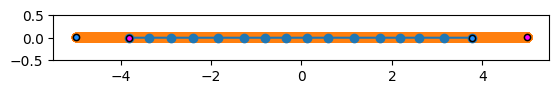

In [286]:
fig, ax = plt.subplots()

# hydraulic centreline 1
# lbc centreline 1. 
hyd_ct1 = list_hydraulic_ct[0][0]
lbc_ct1 = list_lbc_ct[0][0]

ax.plot(*lbc_ct1[:, [0,1]].T, "-o")
ax.plot(*hyd_ct1[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1[-1, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Here the start and end of our lines are reversed, so the discrete frechet metric is quite large. 
We would have to take the minimum of the two. Also, we have to be careful of the recursion depth in checking the coupling distances. 
The hydraulic centreline is very densely sampled, perhaps too densely. We could resample it to a step of 0.1 and calculate the frechet metric then. 

In [287]:
# naive calculation using near identical lines, but parametrised in opposite directions, under
# condition of monotonic increasing parametrisation.
frdist(parametrise_ct(hyd_ct1, nt=50), lbc_ct1)

np.float64(8.78411846321329)

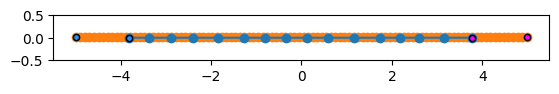

In [288]:
fig, ax = plt.subplots()

# hydraulic centreline 1
# lbc centreline 1. 
hyd_ct1 = list_hydraulic_ct[0][0]
lbc_ct1 = list_lbc_ct[0][0]

ax.plot(*lbc_ct1[:, [0,1]].T, "-o")
ax.plot(*parametrise_ct(hyd_ct1)[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1[-1, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1[0, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Intuitively in this example, the discrete frechet distance metric between these two parallel lines should be near equal to the maximum of the distance between the start points or end points.

In [289]:
frdist(parametrise_ct(hyd_ct1, nt=50), lbc_ct1[::-1])

np.float64(1.2122317033164063)

We can check this is the case: 

In [290]:
print("distance between start points: ", np.linalg.norm(lbc_ct1[-1] - hyd_ct1[0]))
print("distance between end points: ", np.linalg.norm(lbc_ct1[0] - hyd_ct1[-1]))

distance between start points:  1.1863784769533867
distance between end points:  1.2122317033164063


Trimming: we may have to use the best of both worlds... 

In [291]:
def trim_adjust(ct1, ct2):
    # we essentially reparametrise the lines to begin as close as possible. 

    ct1_ct2_nearest = np.argmin(np.linalg.norm(ct1[0] - ct2[[0, -1], :], axis =1))
    # this is only zero, or one. 
    flip = 1
    if ct1_ct2_nearest ==1:
        flip = -1

    ct1_parametrised = parametrise_ct(ct1, nt= 1000)
    ct2_parametrised = parametrise_ct(ct2[::flip], nt=1000)

    # check whether a point in ct1 is closer to ct2_0. if so, we have to trim until there.
    idx_ct1_1 = np.argmin(np.linalg.norm(ct2[::flip][0] - ct1_parametrised,  axis=1))
    idx_ct2_1 = np.argmin(np.linalg.norm(ct1[0] - ct2_parametrised,  axis=1))

    idx_ct1_2 = np.argmin(np.linalg.norm(ct2[::flip][-1] - ct1_parametrised,  axis=1))
    idx_ct2_2 = np.argmin(np.linalg.norm(ct1[-1] - ct2_parametrised,  axis=1))

    return ct1_parametrised[idx_ct1_1:idx_ct1_2], ct2_parametrised[idx_ct2_1:idx_ct2_2] 

In [292]:
hyd_ct1_t, lbc_ct1_t = trim_adjust(hyd_ct1, lbc_ct1)

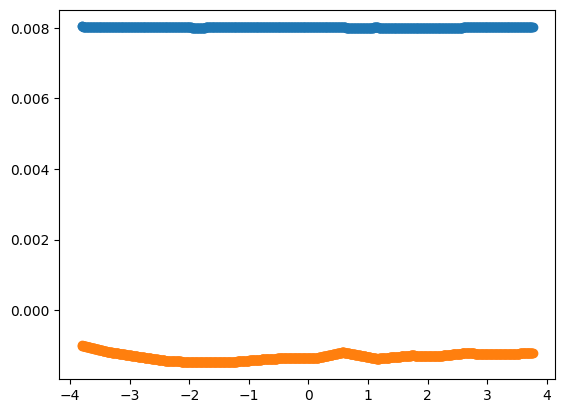

In [293]:
plt.plot(*hyd_ct1_t[:,[0,1]].T, "-o")
plt.plot(*lbc_ct1_t[:,[0,1]].T, "-o")

Therefore, we have to trim the frechet metric calculation to the portions of centreline that overlap. 

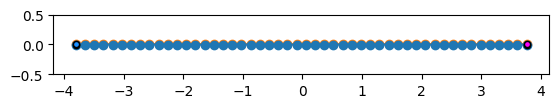

In [294]:
fig, ax = plt.subplots()


ax.plot(*parametrise_ct(lbc_ct1_t, nt = 50)[:, [0,1]].T, "-o")
ax.plot(*parametrise_ct(hyd_ct1_t, nt=50)[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1_t[0, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1_t[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1_t[-1, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1_t[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Now that the two centrelines overlap, the discrete frechet metric is dominated by the largest spacing between two nodes of each centreline. If one is densely sampled, and the other not, then the discrete frechet metric describes the larger of the two sampling intervals. 

In [295]:
# print an example of dense sampling one side, vs coarse on the other: 
print("hydraulic: 100 nodes, lbc: 30,  ", frdist(parametrise_ct(hyd_ct1_t, nt=100), parametrise_ct(lbc_ct1_t, 30)))
print("hydraulic: 500 nodes, lbc: 30,  ", frdist(parametrise_ct(hyd_ct1_t, nt=500), parametrise_ct(lbc_ct1_t, 30)))
print("hydraulic: 950 nodes, lbc: 30,  ", frdist(parametrise_ct(hyd_ct1_t, nt=950), parametrise_ct(lbc_ct1_t, 30)))
print("hydraulic: 100 nodes, lbc: 100,  ", frdist(parametrise_ct(hyd_ct1_t, nt=50), parametrise_ct(lbc_ct1_t, 50)))
print("hydraulic: 100 nodes, lbc: 100,  ", frdist(parametrise_ct(hyd_ct1_t, nt=100), parametrise_ct(lbc_ct1_t, 100)))
print("hydraulic: 200 nodes, lbc: 200,  ", frdist(parametrise_ct(hyd_ct1_t, nt=200), parametrise_ct(lbc_ct1_t, 200)))


hydraulic: 100 nodes, lbc: 30,   0.130558864107528
hydraulic: 500 nodes, lbc: 30,   0.13079620424134233
hydraulic: 950 nodes, lbc: 30,   0.13080735910912208
hydraulic: 100 nodes, lbc: 100,   0.010505481156315683
hydraulic: 100 nodes, lbc: 100,   0.01050782204691044
hydraulic: 200 nodes, lbc: 200,   0.010508929803807122


Clearly, we need at least to sample each polyline densely. The more dense the sampling, the closer we may approach the actual frechet distance between the two curves. 

In [296]:
def prepare_frechet(list1, list2, nt):
    clean_list1 = []
    clean_list2 = []
    # parametrise, clip, flip.
    for ct1, ct2 in zip(list1, list2):
        # always trim ct1. 
        ct1_t, ct2_t = trim_adjust(ct1, ct2)
        

        clean_list1.append(parametrise_ct(ct1_t, nt=nt))
        clean_list2.append(parametrise_ct(ct2_t, nt))
    
    return clean_list1, clean_list2

In [297]:
# comparison between all two possible combinations. (2 choose 5)
hyd1_to_lbc = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[0] for elem in list_lbc_ct], 200)
hyd2_to_lbc = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_lbc_ct], 200)
hyd1_to_mst = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[0] for elem in list_mst_ct], 200)
hyd2_to_mst = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_mst_ct], 200)
hyd1_to_iter = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[0] for elem in list_iter_ct], 200)
hyd2_to_iter = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_iter_ct], 200)
hyd1_to_hyd2 = prepare_frechet([elem[0] for elem in list_hydraulic_ct], [elem[3] for elem in list_hydraulic_ct], 200)
mst_to_lbc = prepare_frechet([elem[0] for elem in list_mst_ct], [elem[0] for elem in list_lbc_ct], 200)
iter_to_lbc = prepare_frechet([elem[0] for elem in list_lbc_ct], [elem[0] for elem in list_iter_ct], 200)
iter_to_mst = prepare_frechet([elem[0] for elem in list_mst_ct], [elem[0] for elem in list_iter_ct], 200)


In [298]:
comparison_map = {0: hyd1_to_lbc,
                  1: hyd2_to_lbc,
                  2: hyd1_to_mst, 
                  3:hyd2_to_mst, 
                  4:hyd1_to_iter,
                  5:hyd2_to_iter,
                  6:hyd1_to_hyd2, 
                  7:mst_to_lbc, 
                  8:iter_to_lbc,
                  9:iter_to_mst}

In [299]:
fr_results_hydraulic = -np.ones((10,9))

In [300]:
for i, (ct1, ct2) in enumerate(zip(*hyd1_to_lbc)):
    fr_results_hydraulic[0, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_lbc)):
    fr_results_hydraulic[1, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd1_to_mst)):
    fr_results_hydraulic[2, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_mst)):
    fr_results_hydraulic[3, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd1_to_iter)):
    fr_results_hydraulic[4, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_iter)):
    fr_results_hydraulic[5, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*hyd1_to_hyd2)):
    fr_results_hydraulic[6, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*mst_to_lbc)):
    fr_results_hydraulic[7, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*iter_to_lbc)):
    fr_results_hydraulic[8, i] = frdist(ct1, ct2)
for i, (ct1, ct2) in enumerate(zip(*iter_to_mst)):
    fr_results_hydraulic[9, i] = frdist(ct1, ct2)

In [301]:
xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "faux monnayeurs","méandre", "môtiers"]
ylabels = ["flow sim 1 / lbc", "flow sim 2 / lbc", " flow sim 1 / mst", "flow sim 2 / mst", "flow sim 1 / iter", "flow sim 2 / iter", "flow sim 1 / flow sim 2", "mst / lbc", "iter / lbc", "iter / mst"]

Text(0.5, 1.0, 'centreline comparison matrix')

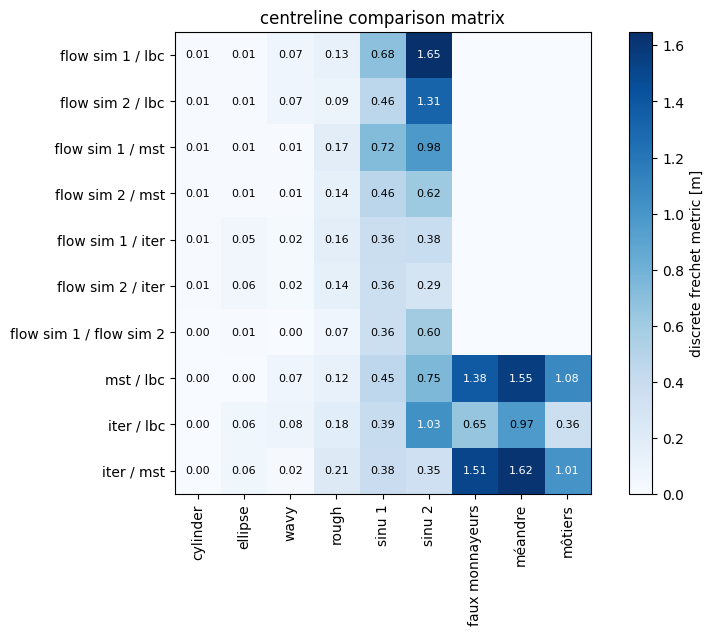

In [302]:
fig, ax = plt.subplots(figsize = (10,6))

im = ax.imshow(fr_results_hydraulic, cmap = "Blues", vmin=0)
ax.set_xticks([0,1,2,3,4,5,6,7,8])
ax.set_yticks([0,1,2,3,4,5,6,7,8,9])

for j, row in enumerate(fr_results_hydraulic):
    for i, elem in enumerate(row):
        color = "k"
        if elem > np.quantile(fr_results_hydraulic, 0.9):
            color = "white"
        if elem > 0:

            ax.text(i,j, f"{elem:.2f}", fontsize = 8, va = "center", ha="center", color =color)
ax.set_xticklabels(xlabels, rotation =90)
ax.set_yticklabels(ylabels)
cax = plt.colorbar(im)
cax.set_label("discrete frechet metric [m]")
ax.set_title("centreline comparison matrix")

In [224]:
from stl import mesh

In [303]:
# list all meshes. 
list_meshes = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"./data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))

In [310]:
def plot_compare(comp_list, comp_id, conduit,labels, ylim=0.5,zlim=0.5,  figsize = (8,8)):
    fig, axes = plt.subplots(2,1, figsize = figsize)
    ax = axes[0]
    ax.plot(*comp_list[0][conduit][:, [0,1]].T, "-o", markersize =2, lw = 0.5, label = labels[0])
    ax.plot(*comp_list[1][conduit][:, [0,1]].T, "-o", zorder = -10,  markersize =2, lw = 0.5, label = labels[1])
    ax.scatter(*comp_list[0][conduit][0, [0,1]], **start_kwargs)
    ax.scatter(*comp_list[1][conduit][-1, [0,1]], **end_kwargs)

    ax.scatter(*list_meshes[conduit].centroids[::50, [0,1]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_ylim(-ylim, ylim)
    
    ax.set_title(f"fréchet metric: {fr_results_hydraulic[comp_id, conduit]:.2f}", fontsize=9, loc = "right")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.legend(loc = "lower left", bbox_to_anchor=(0.02, 1.02))
    ax.scatter(*comp_list[0][conduit][-1, [0,1]], **end_kwargs)
    ax.scatter(*comp_list[1][conduit][0, [0,1]], **start_kwargs)

    ax = axes[1]
    ax.plot(*comp_list[0][conduit][:, [0,2]].T, "-o", markersize =2, lw = 0.5, label = labels[0])
    ax.plot(*comp_list[1][conduit][:, [0,2]].T, "-o", zorder = -10,  markersize =2, lw = 0.5, label = labels[1])
    ax.scatter(*comp_list[0][conduit][0, [0,2]], **start_kwargs)
    ax.scatter(*comp_list[1][conduit][-1, [0,2]], **end_kwargs)

    ax.scatter(*list_meshes[conduit].centroids[::50, [0,2]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_ylim(-zlim, zlim)
    
    ax.set_title(f"fréchet metric: {fr_results_hydraulic[comp_id, conduit]:.2f}", fontsize=9, loc = "right")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("z [m]")
    ax.legend(loc = "lower left", bbox_to_anchor=(0.02, 1.02))
    ax.scatter(*comp_list[0][conduit][-1, [0,2]], **end_kwargs)
    ax.scatter(*comp_list[1][conduit][0, [0,2]], **start_kwargs)
    return fig, ax

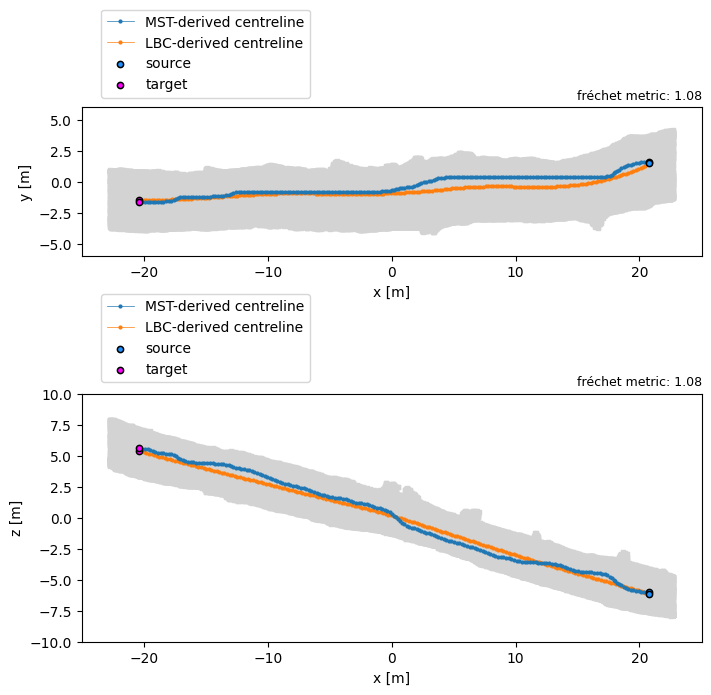

In [311]:
plot_compare(mst_to_lbc,7, 8, ("MST-derived centreline", "LBC-derived centreline"),6, 10)
plt.savefig("./temp/figures/Motiers_comparison.png")

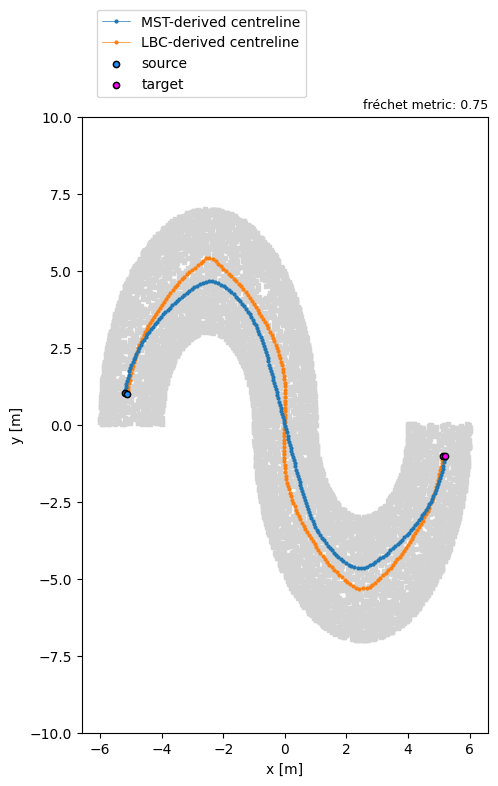

In [255]:
plot_compare(mst_to_lbc,7, 5, ("MST-derived centreline", "LBC-derived centreline"),10)
plt.savefig("./temp/figures/Extrasinuous_comparison.png")

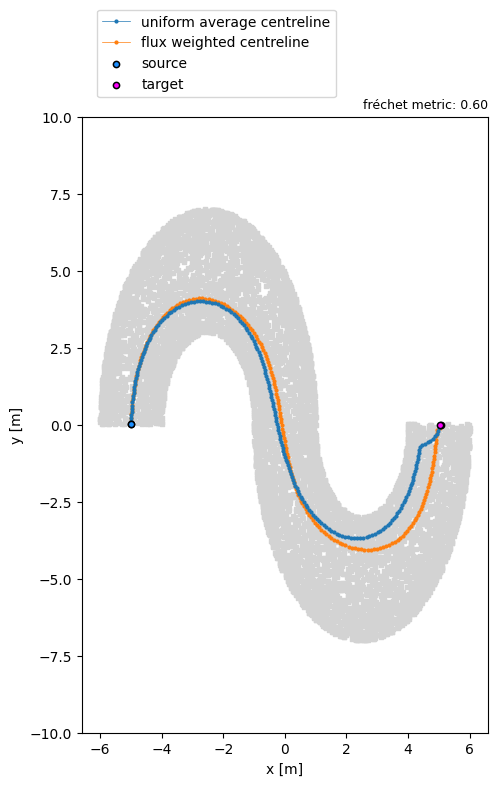

In [256]:
plot_compare(hyd1_to_hyd2,6, 5, ("uniform average centreline", "flux weighted centreline"),10)
plt.savefig("./temp/figures/Extrasinuous_comparison2.png")

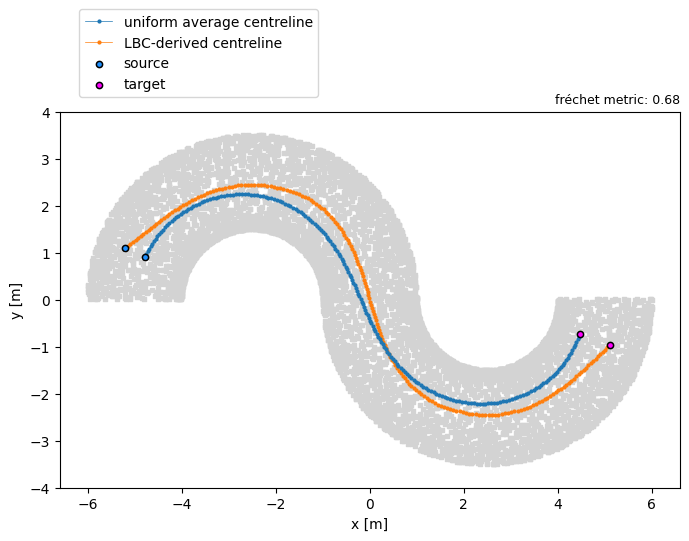

In [257]:
plot_compare(hyd1_to_lbc,0, 4, ("uniform average centreline", "LBC-derived centreline"),4)
plt.savefig("./temp/figures/Sinuous_comparison.png")

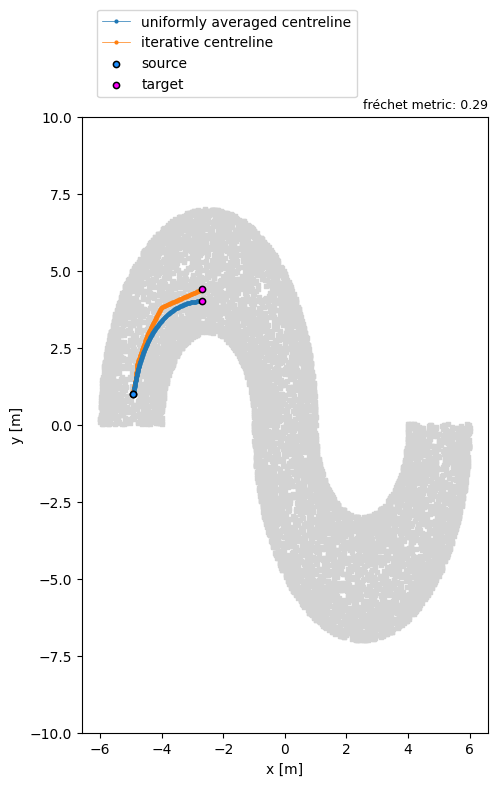

In [259]:
plot_compare(hyd1_to_iter,5, 5, ("uniformly averaged centreline", "iterative centreline"),10)
plt.savefig("./temp/figures/Extrasinuous_comparison3.png")

In [258]:
plot_compare(iter_to_lbc,8, 1)

TypeError: plot_compare() missing 1 required positional argument: 'labels'

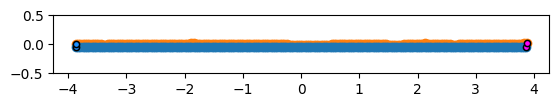

In [187]:
plot_compare(iter_to_lbc, 2)

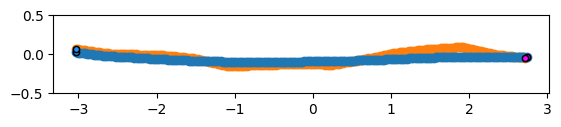

In [188]:
plot_compare(iter_to_lbc, 3)

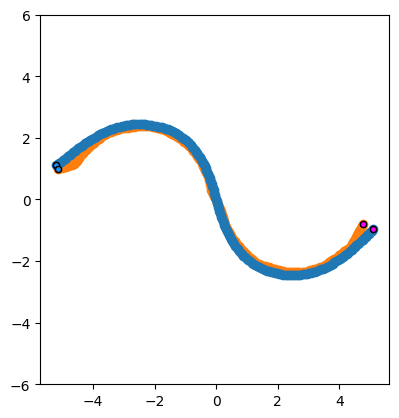

In [ ]:
plot_compare(iter_to_lbc, 4,6)

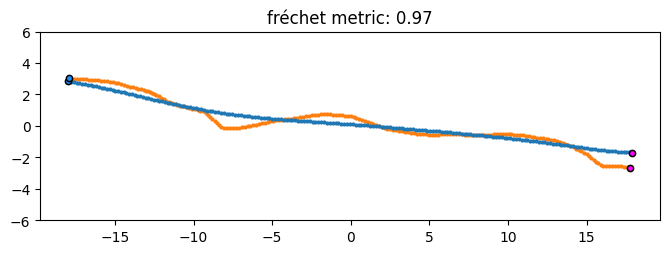

In [220]:
plot_compare(iter_to_lbc,8, 7,6)

In [190]:
np.savetxt("./temp/synthetic/frdist_hydraulic_validation.txt", fr_results_hydraulic)